# ***Μέρος 1 – KNN***




---


# **Ερώτημα 1**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.model_selection import train_test_split
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np

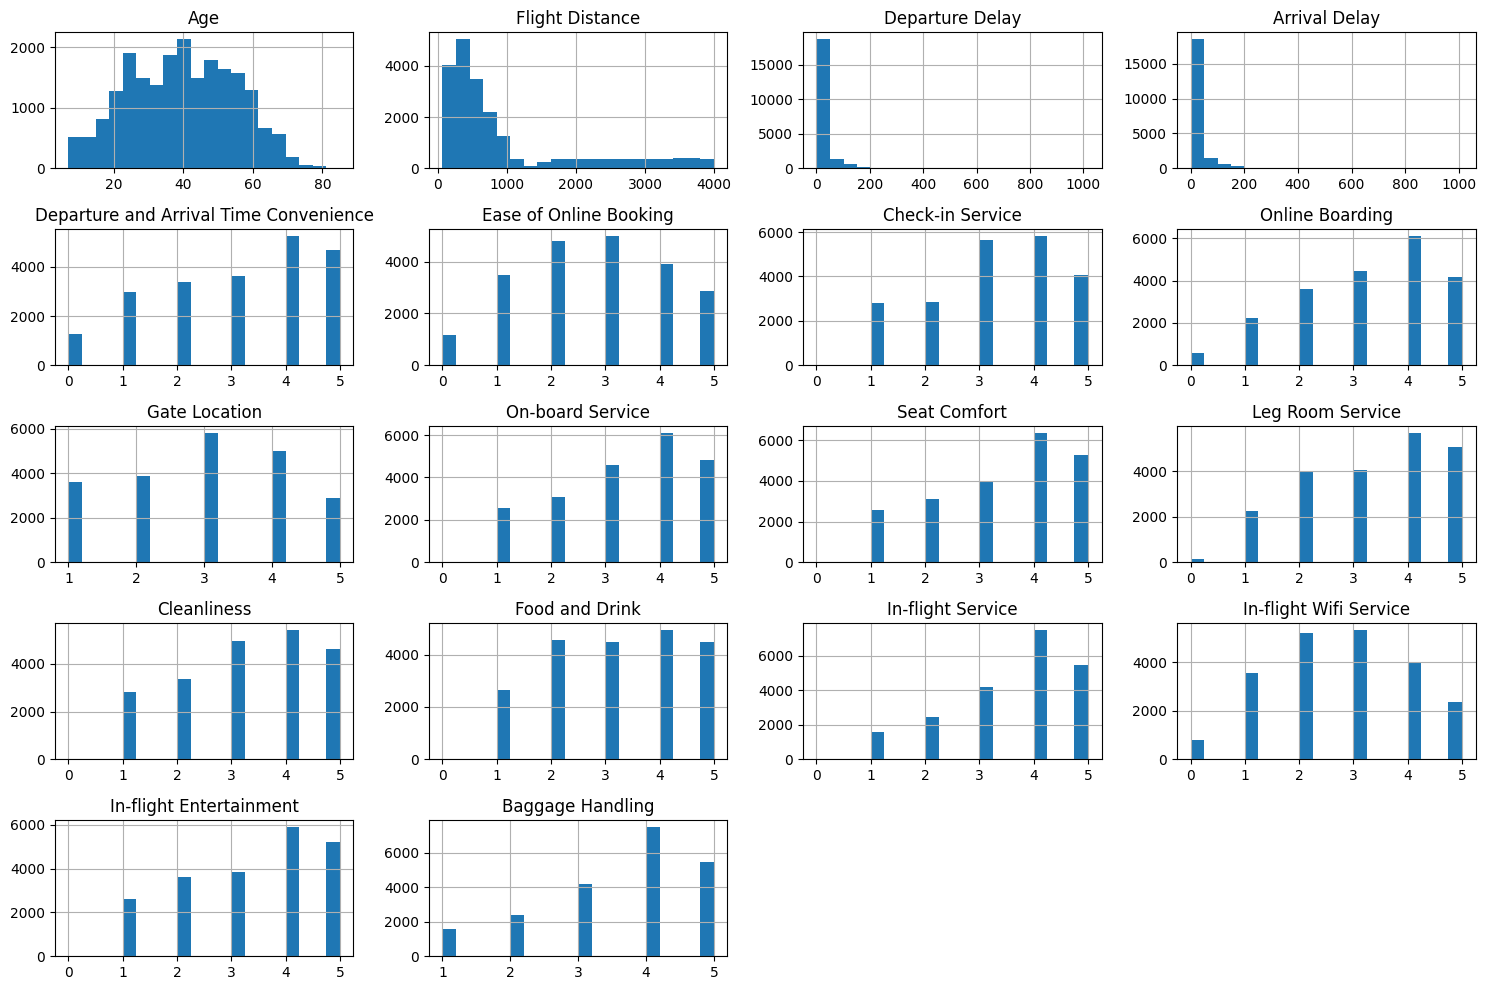

In [3]:
df = pd.read_csv("airline_passenger_satisfaction.csv")
df = df.drop(columns=["ID"], errors="ignore")
df = df.dropna()

numeric = df.select_dtypes(include="number").columns
df[numeric].hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.grid(False)
plt.show()

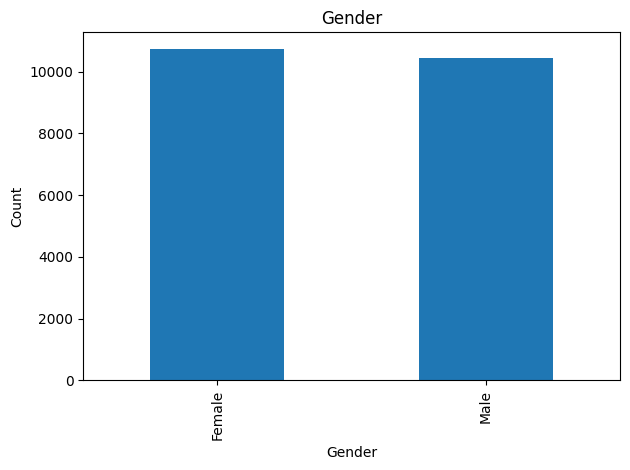

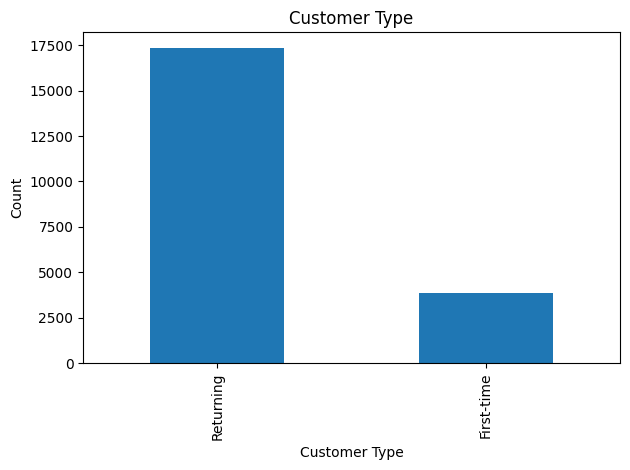

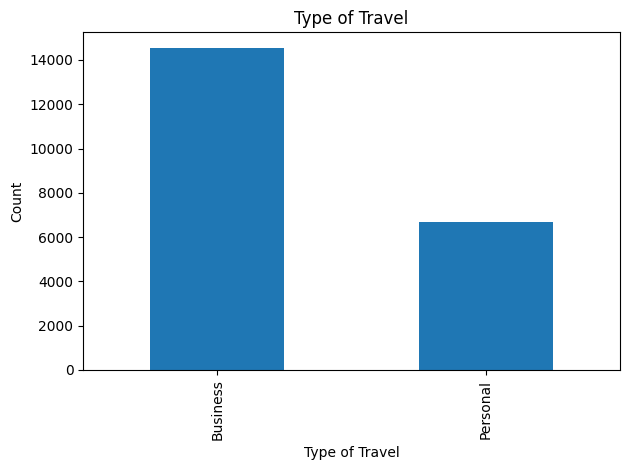

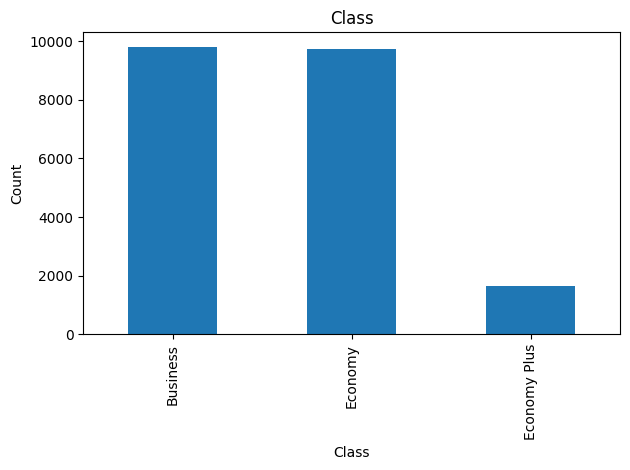

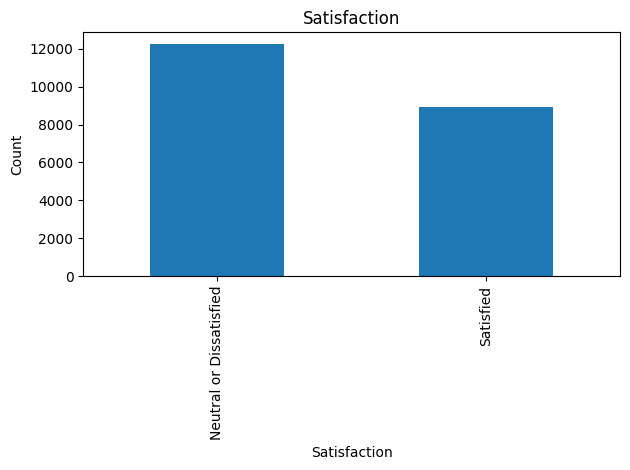

In [4]:
categorical = df.select_dtypes(include="object").columns

for col in categorical:
    df[col].value_counts().plot(kind="bar", title=col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

Από το ραβδόγραμμα της μεταβλητής Satisfaction φαίνεται ότι οι δύο κατηγορίες δεν είναι ισορροπημένες, καθώς υπάρχουν περισσότεροι επιβάτες στην κατηγορία "Neutral or Dissatisfied" από ότι στην κατηγορία "Satisfied".



---


# **Ερώτημα 2**

In [5]:
df = pd.get_dummies(df,columns=df.select_dtypes(include="object").columns.drop("Satisfaction"),dtype=int)

df["Satisfaction"] = df["Satisfaction"].map({"Neutral or Dissatisfied": 0,"Satisfied": 1})

print(df.shape)
print(df["Satisfaction"].value_counts(dropna=False))

(21189, 28)
Satisfaction
0    12253
1     8936
Name: count, dtype: int64




---


# **Ερώτημα 3**

In [6]:
df = df.dropna(subset=["Satisfaction"])

X = df.drop("Satisfaction", axis=1).to_numpy()
y = df["Satisfaction"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(14832, 27) (6357, 27)
(14832,) (6357,)


In [7]:
print(df.select_dtypes(include="object").columns)
print(df["Satisfaction"].unique())
print(X_train[0])

Index([], dtype='object')
[0 1]
[ 30. 599.  14.   7.   1.   1.   3.   4.   1.   5.   5.   4.   5.   5.
   5.   1.   5.   5.   1.   0.   0.   1.   1.   0.   1.   0.   0.]




---


# **Ερώτημα 4**

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[:, :18] = scaler.fit_transform(X_train[:, :18])
X_test[:, :18] = scaler.transform(X_test[:, :18])

Χρησιμοποιούμε το StandardScaler για να έχουν οι αριθμητικές μεταβλητές μέσο όρο 0 και τυπική απόκλιση 1. Αυτό είναι απαραίτητο για τον KNN, επειδή βασίζεται στις αποστάσεις μεταξύ των δεδομένων και οι μεταβλητές με μεγαλύτερες τιμές θα μπορούσαν διαφορετικά να επηρεάζουν περισσότερο το αποτέλεσμα.



---


# **Ερώτημα 5**

In [9]:
N = len(X_train)
k_values = [3, 5, 15, 51, 151, int(np.sqrt(N))]
weights = ["uniform", "distance"]

results = []

for k in k_values:
    for w in weights:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric="euclidean")
        knn.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, knn.predict(X_train))
        test_acc = accuracy_score(y_test, knn.predict(X_test))

        results.append([k, w, train_acc, test_acc])

results = pd.DataFrame(results, columns=["k", "Weights", "Train Accuracy", "Test Accuracy"])

print(results)
print("\nBest combination:")
print(results.loc[results["Test Accuracy"].idxmax()])

      k   Weights  Train Accuracy  Test Accuracy
0     3   uniform        0.949501       0.911279
1     3  distance        1.000000       0.911279
2     5   uniform        0.938646       0.916627
3     5  distance        1.000000       0.917099
4    15   uniform        0.921319       0.918515
5    15  distance        1.000000       0.919302
6    51   uniform        0.907565       0.903885
7    51  distance        1.000000       0.905616
8   151   uniform        0.892665       0.890514
9   151  distance        1.000000       0.892874
10  121   uniform        0.896238       0.894132
11  121  distance        1.000000       0.896492

Best combination:
k                       15
Weights           distance
Train Accuracy         1.0
Test Accuracy     0.919302
Name: 5, dtype: object




---
# ***Μέρος 2 – Πρόβλεψη Χρονοσειρών***



In [ ]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

# **Ερώτημα 1**

In [ ]:
ticker_symbol = 'DX-Y.NYB'


ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df
df[['Open', 'High', 'Low', 'Close']].describe().loc[['mean', 'std']]

,Date,Open,High,Low,Close
0,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
1,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
2,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
3,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
4,2016-11-07 00:00:00-05:00,97.540001,97.870003,97.220001,97.779999
...,...,...,...,...,...
2509,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2510,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2511,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002
2512,2026-10-29 00:00:00-04:00,102.080002,102.449997,101.849998,102.040001


Οι μεταβλητές OHLCV περιγράφουν την ημερήσια κίνηση ενός χρηματοοικονομικού προϊόντος:
- Open: τιμή ανοίγματος.
- High: υψηλότερη τιμή της ημέρας.
- Low: χαμηλότερη τιμή της ημέρας.
- Close: τιμή κλεισίματος.
- Volume: όγκος συναλλαγών κατά τη διάρκεια της ημέρας.

Η μέση τιμή (mean) δείχνει τη μέση τιμή της κάθε μεταβλητής για το χρονικό διάστημα που εξετάζεται, ενώ η τυπική απόκλιση (standard deviation) δείχνει τη διασπορά των τιμών γύρω από τη μέση τιμή

In [ ]:
fig = px.line(df,x='Date',y=['High', 'Low', 'Close'],title='USD Index - High, Low, Close (Last 10 Years)',
    width=1200,
    height=700
)

fig.show()



---


# **Ερώτημα 2**

Από το διάγραμμα, οι χρονοσειρές φαίνονται μη στάσιμες, καθώς οι τιμές τους μεταβάλλονται σε διαφορετικά επίπεδα με την πάροδο του χρόνου και δεν παρουσιάζουν σταθερή μέση τιμή



---


# **Ερώτημα 3**

In [ ]:
for col in ['High', 'Low', 'Close']:
    series = df[col].dropna()

    adf_p = adfuller(series)[1]
    kpss_p = kpss(series, regression='c', nlags='auto')[1]

    print(col, '- ADF:', adf_p, '- KPSS:', kpss_p)

High - ADF: 0.33232458775021856 - KPSS: 0.01
Low - ADF: 0.2876305280370497 - KPSS: 0.01
Close - ADF: 0.33524128763349964 - KPSS: 0.01


/tmp/ipykernel_2326/567625993.py:4: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

/tmp/ipykernel_2326/567625993.py:5: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_2326/567625993.py:5: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current beh

---
# **Ερώτημα 4**

In [ ]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0] * train_size)

train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

---
# **Ερώτημα 5**

In [ ]:
H = [1, 5, 15, 30]
results = []

for h in H:
    data = df[['Open', 'High', 'Low', 'Close']].copy()
    data['Target'] = df['Close'].shift(-h)
    data = data.dropna()

    split = int(len(df) * 0.7)
    train_df = data.iloc[:split]
    test_df = data.iloc[split:]

    x_train = train_df[['Open', 'High', 'Low', 'Close']]
    y_train = train_df['Target']

    x_test = test_df[['Open', 'High', 'Low', 'Close']]
    y_test = test_df['Target']

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_pred = model.predict(x_train)
    train_mae = mean_absolute_error(y_train, y_pred)

    y_pred = model.predict(x_test)
    test_mae = mean_absolute_error(y_test, y_pred)

    results.append({
        'H': h,
        'Train MAE': train_mae,
        'Test MAE': test_mae
    })

metrics_df = pd.DataFrame(results)
metrics_df

,H,Train MAE,Test MAE
0,1,0.310284,0.308758
1,5,0.692043,0.680746
2,15,1.167420,1.178408
3,30,1.670036,1.739288


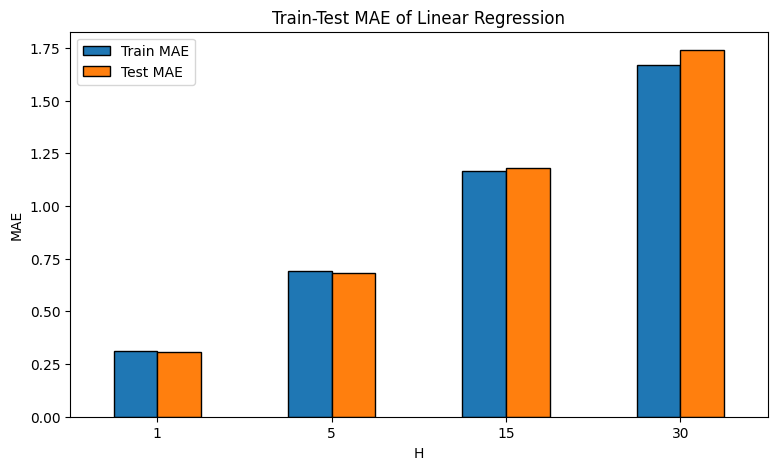

In [ ]:
metrics_df.plot(
    x='H',
    y=['Train MAE', 'Test MAE'],
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Train-Test MAE of Linear Regression')
plt.xlabel('H')
plt.ylabel('MAE')
plt.xticks(rotation=0)
plt.show()

---
# **Ερώτημα 6**

In [ ]:

H = 30
train_pred = model.predict(x_train)
test_pred = model.predict(x_test)

train_dates = df['Date'].iloc[:len(y_train)]
test_dates = df['Date'].iloc[len(y_train):len(y_train) + len(y_test)]

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=train_dates.iloc[-30:],
    y=np.ravel(y_train)[-30:],
    mode='lines',
    name='Train (Actual)'
))

fig.add_trace(go.Scatter(
    x=train_dates.iloc[-30:],
    y=np.ravel(train_pred)[-30:],
    mode='lines',
    name='Train (Predicted)'
))

fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(dash='dash')
))

fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(test_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='red', width=2)
))

fig.update_layout(
    title='USD Close Price Prediction (H=30)',
    xaxis_title='Date',
    yaxis_title='Close Price',
    template='plotly_white',
    hovermode='x unified'
)

fig.show()

Οι προβλεπόμενες τιμές ακολουθούν σε γενικές γραμμές την τάση των πραγματικών τιμών, παρουσιάζουν όμως αποκλίσεις, ιδιαίτερα σε περιόδους έντονων μεταβολών. Αυτό δείχνει ότι για H=30 το μοντέλο δυσκολεύεται να προβλέψει με ακρίβεια τις απότομες αλλαγές της χρονοσειράς.


---
# **Ερώτημα 7**

In [ ]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [ ]:
df_logr = np.log(df[['Open', 'High', 'Low', 'Close']] /
                 df[['Open', 'High', 'Low', 'Close']].shift(1)).dropna()

In [ ]:
log_returns_to_absolute_prices(
    prices=df['Close'].iloc[:-1].to_numpy(),
    log_returns=df_logr['Close'].to_numpy()
)

array([ 97.40000153,  97.16000366,  97.06999969, ..., 102.19000244,
       102.04000092, 101.87999725])

In [ ]:
H = [1, 5, 15, 30]
features = ['Open', 'High', 'Low', 'Close']

results_log = []

for h in H:
    data = df_logr.copy()

    data['Target'] = np.log(df['Close'].shift(-h) / df['Close'])
    data = data.dropna()
    split = int(len(data) * 0.7)

    train = data.iloc[:split]
    test = data.iloc[split:]

    X_train = train[features]
    y_train = train['Target']

    X_test = test[features]
    y_test = test['Target']

    model = LinearRegression()
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_prices = df.loc[train.index, 'Close'].to_numpy()
    test_prices = df.loc[test.index, 'Close'].to_numpy()

    train_actual = df['Close'].shift(-h).loc[train.index].to_numpy()
    test_actual = df['Close'].shift(-h).loc[test.index].to_numpy()

    train_pred_absolute = log_returns_to_absolute_prices(
        train_prices, train_pred
    )

    test_pred_absolute = log_returns_to_absolute_prices(
        test_prices, test_pred
    )

    train_mae = mean_absolute_error(train_actual, train_pred_absolute)
    test_mae = mean_absolute_error(test_actual, test_pred_absolute)

    results_log.append([h, train_mae, test_mae])

results_log_df = pd.DataFrame(
    results_log,
    columns=['H', 'Train MAE Log-Returns', 'Test MAE Log-Returns']
)

results_log_df

,H,Train MAE Log-Returns,Test MAE Log-Returns
0,1,0.309619,0.307870
1,5,0.693357,0.686845
2,15,1.172102,1.211538
3,30,1.692466,1.814125


---
# **Ερώτημα 8**

In [ ]:
data = train_df[['Close', 'Open']]

data = np.log(data / data.shift(1)).dropna()

results = grangercausalitytests(
    data[['Close', 'Open']],
    maxlag=history_size,)

p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}

results_df = pd.DataFrame({
    'Lag (H)': list(p_values.keys()),
    'P-value': list(p_values.values())
})

results_df['Significant'] = results_df['P-value'] < 0.05

results_df

,Lag (H),P-value,Significant
0,1,0.191609,False
1,2,0.820257,False
2,3,0.525268,False
3,4,0.785338,False
4,5,0.025691,True
5,6,0.636667,False
6,7,0.725205,False
7,8,0.392926,False
8,9,0.278278,False
9,10,0.493648,False


---
# **Ερώτημα 9**

In [ ]:

df['Date'] = pd.to_datetime(df['Date']).dt.tz_localize(None)


df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek


us_holidays = holidays.country_holidays('US')

df['Holiday'] = df['Date'].dt.date.map(
    lambda d: int(d in us_holidays)
)


sp500 = yf.download(
    '^GSPC',
    start=df['Date'].min(),
    end=df['Date'].max(),
    auto_adjust=True
)

sp500 = sp500[['Close']].reset_index()
sp500.columns = ['Date', 'SP500']
sp500['Date'] = pd.to_datetime(sp500['Date']).dt.tz_localize(None)


df = df.merge(sp500, on='Date', how='left')
df['SP500'] = df['SP500'].ffill()

df.head()

[*********************100%***********************]  1 of 1 completed


,Date,Open,High,Low,Close,Month,DayOfWeek,Holiday,SP500
0,2016-11-01,98.389999,98.480003,97.639999,97.699997,11,1,0,2111.719971
1,2016-11-02,97.750000,97.800003,97.180000,97.400002,11,2,0,2097.939941
2,2016-11-03,97.379997,97.459999,97.040001,97.160004,11,3,0,2088.659912
3,2016-11-04,97.160004,97.349998,96.889999,97.070000,11,4,0,2085.179932
4,2016-11-07,97.540001,97.870003,97.220001,97.779999,11,0,0,2131.520020


In [ ]:
H = 30


df['FutureMonth'] = df['Month'].shift(-H)
df['FutureDayOfWeek'] = df['DayOfWeek'].shift(-H)
df['FutureHoliday'] = df['Holiday'].shift(-H)


df['Target'] = df['Close'].shift(-H)

data = df.dropna().copy()

In [ ]:
features = [
    'Open', 'High', 'Low', 'Close',
    'SP500',
    'Month', 'DayOfWeek', 'Holiday',
    'FutureMonth', 'FutureDayOfWeek', 'FutureHoliday'
]

split = int(len(data) * 0.7)

train_df = data.iloc[:split]
test_df = data.iloc[split:]

x_train = train_df[features]
y_train = train_df['Target']

x_test = test_df[features]
y_test = test_df['Target']


model = LinearRegression()
model.fit(x_train, y_train)

train_pred = model.predict(x_train)
test_pred = model.predict(x_test)

In [ ]:
fig = go.Figure()


fig.add_trace(go.Scatter(
    x=train_df['Date'].iloc[-30:],
    y=y_train.iloc[-30:],
    mode='lines',
    name='Train (Actual)'
))


fig.add_trace(go.Scatter(
    x=train_df['Date'].iloc[-30:],
    y=train_pred[-30:],
    mode='lines',
    name='Train (Predicted)'
))


fig.add_trace(go.Scatter(
    x=test_df['Date'],
    y=y_test,
    mode='lines',
    name='Test (Actual)',
    line=dict(dash='dash')
))


fig.add_trace(go.Scatter(
    x=test_df['Date'],
    y=test_pred,
    mode='lines',
    name='Test (Predicted)'
))

fig.update_layout(
    title='USD Close Price Prediction with Additional Features (H=30)',
    xaxis_title='Date',
    yaxis_title='Close Price',
    template='plotly_white',
    hovermode='x unified',
    width=1200,
    height=650
)

fig.show()